In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

In [4]:
def parse_buf(buf):
    full = np.frombuffer(buf, dtype = np.uint16)
    # convert to m (given in mm)
    dists = full[:360] / 1000
    strengths = full[360:]
    theta = np.linspace(0, 2 * np.pi, num=360, endpoint=False)
    return pd.DataFrame({
        'dist': dists,
        'strength': strengths
    }, index=theta)


In [7]:
s1 = parse_buf(bytes.fromhex("cd03cb030000c803c603c403c403c303c4038a038e0393039b03a403ad03b503b703bb03c403c403c903d203d503d903dc03e303f203fd030c0425043f044b045104200430043c045904660476047e048c04a204b304c504dd04ee04f90409052505290543056005760587059d05ac05be05cd05e505f905240654068b06aa06bc0600000000000000000000000000000000000000000000320afd0a5a0bb00b00000000080f190ff80ee80ecd0e500ec20ec20eb70ea00eaa0e1f081c087e0ea80e8e0e0000fe060607930e0000a80eb50ebf0ebf0e4c0f0000dd0e0000000000000000d001ce01ce01cc01ca01ca01c901c801c801c601c701c701c701c701c701c701c601c601c601c601c701c701c801c901c901cb01cb01cd01ce01cf01d101d2010000000000000000000000000000831633160000000000007315701652161b160f168415c3153c154c1510158c14000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000ca01ca01ca010000000000000000960b640b0000000000000000000000000000000000000000c4030000000000000000000000000000000026040000000000000000a4029b029202790283027a0273026d0277028d020000a502d50292067d06710660064e0600003706260615060a060106f505eb05e1050000cf05c805c005b9050000230424042304220422041e041f0422042404270429042c042e04310436043b04400445044b0461046804f30379047f04880400009a04a404ac04ba04dc05e005ed05f70502060c0616062606360641064c0621060e063706570673069c06970612055d063b061606f405d605b8059f0582056a054e05380523050d05fb04e604d704c404b504a6049a048a047c046f04640458044d04420439042f0426041f04180411040a040204fb03f603f003eb03e603e103de03d903d603d403cf0315011601000021011f0111011301ef003b0197008700880086007800a200d400b000ce00d900e700dd00ca00e900cc00ba00c300bb00be00af00a60080009c008900c400d200b0005d008c0087009e0080008b00830082007300900077006f006000750056005f0054006000530058006000520053005000360030003e004a00330000000000000000000a00000000000000000000000000160011000f000b000000000009000900090009000b000d000b000c000b000d000b002f003b000a000a000f00000070001c000a0000000a000c000e001000090000000f000000000000000000be01d8018b010702e5011202fa01bd01d101f6010c029b0197016c016c017501990176019f016a01bb010602fb01c001e601d101eb0100029e01a001a9011c010000000000000000000007000000060007000000000000000600080008000a000c000c000a000a0008000b000b000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000002f00e700290000000000000000000d000600000000003500000000000000000000000a0000000000330000000000000000000000000000002c0000000000000000002a00360035007d0043004200420033001e002d00000060001f003a004d0055005a0066000000580063005c006c0069006c0066006c00000075007c0071007a000000e2000101fe000601a300cf00ec00d500c200ae00a900a50089009500860087008e007b0066008200730041006c0067006a00000064005f006a006000660065006d00730067006f0062006500610056005c001b0044004400390046003e003b005b0000004200540054004c005e00610061006b00740075007f008400860093008f009b0099009a00a000aa00b400b200b100c000c700cb00d900d600e200e400e600e700e900ef00f400ef000101ff000101040107010801fe0005010d01"))

In [8]:
s2 = parse_buf(bytes.fromhex("aa08d608d90892089c08a308b008b608bf08d008ca08d908da08da08ec08f008ef08fe08fa08010904090f0924090000000000000000000000000000000000004d0a720a9c0ab20aae0ab50acc0a330b680b870bad0b020c380c890c9c0ceb0c5d0dfb0d00002507960700000000bf0f860f00006a085d0ff30ead0ec70e5d0e900e670e0000090ede0d020ef10dc20dc90dc00d00000000390437043904370438043b043e043f044304450448044a044b040000fa05f205fe0500060000d905050609061106ca069e0dae0dc50dc50d000000000000020e330e460e6a0e9b0e950ec70eed0e6c0e000000000000000000002f1000009810ac10ee100000070b800b320b0000bb0a1c0b000048054b0551055f0500009404a804c304de0401051b0537050000730593050000761048102210f90fd70fb30f9b0f7a0ff50e930d00000000000000000000000000000000550e0000000000000000380a00000000000000000000000000009a0cdf0200008e0c1b0d180e00000000570d570d0000870c720ced0bcb0bbc0bba0ba90b9a0b910b8a0b7a0b620b580b5c0b6a0b880a750a000000000000df06d3060000ac088208560842085b08a907c605c005920604061c063f0667069606c00628072d0700008305b305ce06b3060000000000000000000000000000000000008d0500000000240600000000000000009204ae040000000000008e040000000000000000000000000000000000005f03000000000000000000000000000000004c030000000000000000000000000000650300006103000000000000000000000000a20466076d0738070000000000000000000000000000000000000000370136013501350100003d013f010000a008c408fa080000f9088c08000000003509db0857090000c409b00993097e0960094e093d091c0913090909f908eb08e108d708cd08c108bc08b108aa089f089b0891088e08870882087e088108d908db08d808de081100080009003200310030002b0031003300340030002e002e002d002c0031002d0033002a002c002e002400230000000000000000000000000000000000000020001c0021002500210020001a00190021001a001f0011001d0018001c00130012000f0000006d00240000000b0000000a00000046000b000b000c000a000f000b000d0000000e001000100019000e000e0012000000000046004f00500052004f00450041003f003500350023001c00110000002a000c001c00120000000d0017000b0016003c000c000e00120012000000000000000f000e0010000b000d000e000b000b000e000000000000000000080008000000070009000700000006000600090000000f0008000000240022001e001e000000070012000c000c000d001a00090008000b000c00000011001300110016001100140015001800180000000000000000000000000000000000000005000000000000000000160000000000000000000000000000001d0040000000110009000600000000001b001c00000012001d000000270027002800280028002a002a002c002d0016001b00150007000c000000000008001c00330000000f00110015002800120017003c003f0000000f002200270025002000240008000a00000073002a000c0009000000000000000000000000000000000000000c00000000000a000000000000000000000007000000000000002200000000003800000000000000000000000000000000000000000000000000000011000f00220000000000000000000000000000001e00210000000000000000000000000000002200070008000a0000000000000000000000000000000000000000003900a100b000290000000000d200000007000500070000000700000000000000000000000000000019002800300028002e0032002b002d00370034003c0038004100390049004500460046003e00420045004c004e00490047004d0047009600720068005300"))

In [9]:
s1

,dist,strength
0.000000,0.973,277
0.017453,0.971,278
0.034907,0.000,0
0.052360,0.968,289
0.069813,0.966,287
...,...,...
6.195919,0.990,263
6.213372,0.985,264
6.230825,0.982,254
6.248279,0.980,261


In [10]:
def graph_scan(df, ax, min_strength, max_dist):
    filtered = df[(df.strength >= min_strength) & (df.dist <= max_dist) & (df.dist != 0)]
    log_strength = np.log(filtered.strength)
    return ax.scatter(filtered.index, filtered.dist, s = 4 * log_strength, c = log_strength, cmap="plasma")
def graph_scan_cart(df, ax, min_strength, max_dist):
    filtered = df[(df.strength >= min_strength) & (df.dist <= max_dist) & (df.dist != 0)]
    log_strength = np.log(filtered.strength)
    return ax.scatter(np.cos(filtered.index) * filtered.dist, np.sin(filtered.index) * filtered.dist, s = 4 * log_strength, c = log_strength, cmap="plasma")

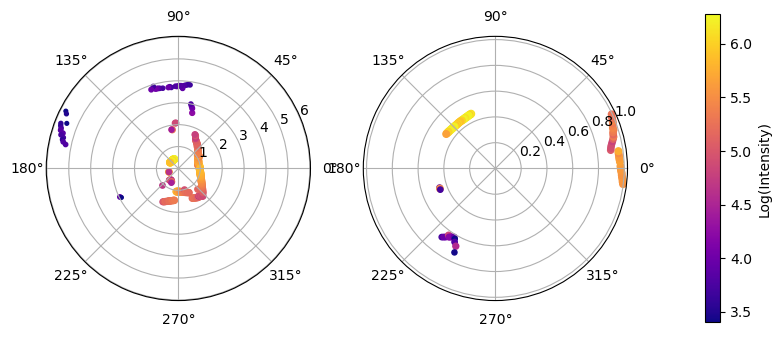

In [11]:
fig, ax = plt.subplots(subplot_kw={"projection": "polar"}, ncols=2, figsize=(10, 5))
s = graph_scan(s1, ax[0], 1, 10)
s = graph_scan(s1, ax[1], 10, 1)

cbar = plt.colorbar(s, ax=ax, pad=0.1, shrink=0.8)
cbar.set_label("Log(Intensity)")

plt.show()

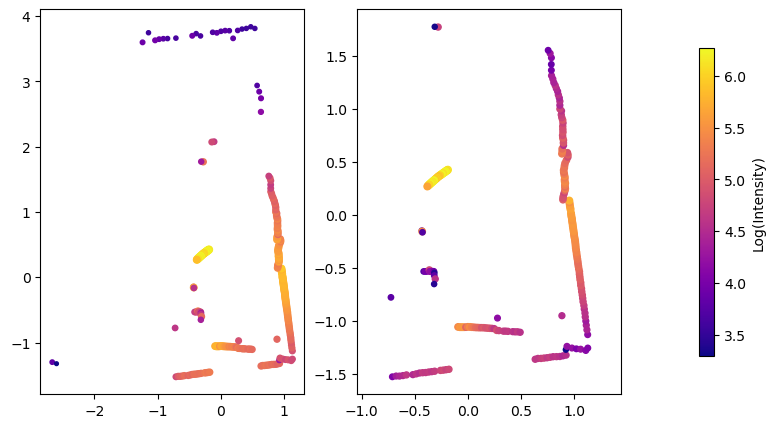

In [12]:
fig, ax = plt.subplots(ncols=2, figsize=(10, 5))
s = graph_scan_cart(s1, ax[0], 1, 5)
s = graph_scan_cart(s1, ax[1], 1, 2)

cbar = plt.colorbar(s, ax=ax, pad=0.1, shrink=0.8)
cbar.set_label("Log(Intensity)")

plt.axis("equal")
plt.show()

In [13]:
print(s1[(s1.dist == 0) & (s1.strength > 0)])

          dist  strength
1.204277   0.0        10
2.635447   0.0         7
3.665191   0.0        53
3.769911   0.0        10
3.822271   0.0        51


In [14]:
s1_noindex = s1.reset_index(names="theta")
f = s1_noindex[(s1_noindex.dist != 0) & (s1_noindex.strength >= 10)]
c1 = pd.DataFrame(
    {
        'x': (np.cos(f.theta) * f.dist).to_numpy(),
        'y': (np.sin(f.theta) * f.dist).to_numpy(),
        'strength': f.strength.to_numpy(),
        'orig_idx': f.index.to_numpy()
    }
)

In [15]:
c1

,x,y,strength,orig_idx
0,0.973000,0.000000,277,0
1,0.970852,0.016946,278,1
2,0.966673,0.050661,289,3
3,0.963647,0.067385,287,4
4,0.960332,0.084018,273,5
...,...,...,...,...
249,0.986233,-0.086284,263,355
250,0.982601,-0.068710,264,356
251,0.980654,-0.051394,254,357
252,0.979403,-0.034202,261,358


In [16]:
def manhat(a, b):
    return np.sum(np.abs(a - b))

points = []
for row in c1.itertuples():
    points.append(np.array([row.x, row.y]))
print(len(points))

254


In [17]:


ranges = []
prev_start = 0
thresh = 2
c1.loc[0, "range"] = 0
for i in range(1, len(points)):
    dist = manhat(points[i], points[i - 1])
    if dist >= thresh:
        ranges.append((prev_start, i))
        prev_start = i
    c1.loc[i, "range"] = len(ranges)
dist_end = manhat(points[0], points[-1])
if dist_end < thresh:
    ranges[0] = (prev_start, len(points) + ranges[0][1])
    for i in range(prev_start, len(points)):
        c1.loc[i, "range"] = 0
else:
    ranges.append((prev_start, len(points)))

ranges

[(131, 334), (80, 82), (82, 88), (88, 120), (120, 127), (127, 130), (130, 131)]

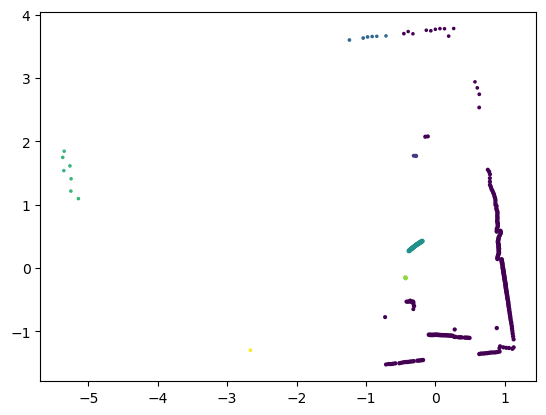

In [18]:
plt.scatter(c1.x, c1.y, s=np.log1p(c1.strength), c = c1.range)
plt.show()

In [19]:
def point_line_dist(p, l1, l2):
    """Squared point-line distance"""
    a = p - l1
    b = l2 - l1
    # Vector projection
    proj = b * (np.dot(a, b) / np.dot(b, b))
    dist_vec = a - proj
    # Return squared dist
    
    return np.dot(dist_vec, dist_vec)
iepf_threshold = (0.05) ** 2

def iepf(old_lines):
    """Ramer Douglas Peucker (iterative end-point fit)"""
    new_lines = []
    done_lines = []
    # Split lines
    for line in old_lines:
        # Endpoints of this line
        l1 = points[line[0] % len(points)]
        l2 = points[(line[1] - 1) % len(points)]
        max_d = 0
        max_i = 0
        # Check each point distance within
        for i in range(line[0] + 1, line[1] - 1):
            d = point_line_dist(points[i % len(points)], l1, l2)
            if d > max_d:
                max_d = d
                max_i = i
        if max_d >= iepf_threshold:
            new_lines.append((line[0], max_i))
            new_lines.append((max_i, line[1]))
        else:
            done_lines.append(line)
        
    return done_lines, new_lines

In [20]:
new_lines = ranges[:]
done_lines = []
stages = []
while len(new_lines) > 0:
    d2, new_lines = iepf(new_lines)
    print(f"Finished {len(d2)} lines, process {len(new_lines)} lines")
    for d in d2:
        if d[1] - d[0] > 1:
            done_lines.append(d)
    stages.append(done_lines + new_lines)
    

Finished 5 lines, process 4 lines
Finished 1 lines, process 6 lines
Finished 2 lines, process 8 lines
Finished 2 lines, process 12 lines
Finished 8 lines, process 8 lines
Finished 6 lines, process 4 lines
Finished 2 lines, process 4 lines
Finished 4 lines, process 0 lines


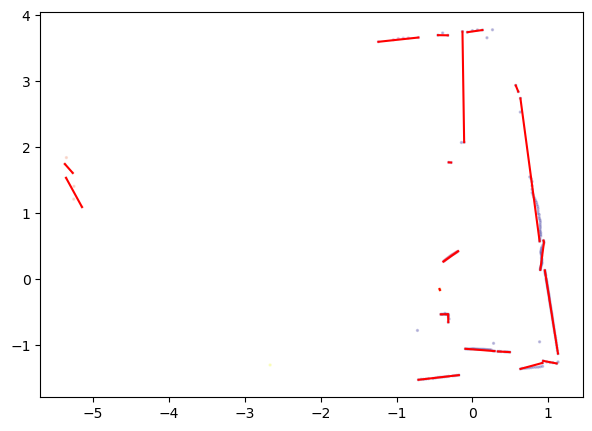

In [21]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(c1.x, c1.y, c=c1.range, cmap="plasma", s = 2, alpha=0.2)
for a, b in done_lines:
    aa = a % len(points)
    bb = (b - 1) % len(points)
    ax.plot([c1.x[aa], c1.x[bb]], [c1.y[aa], c1.y[bb]], color="red")

In [22]:
end_thresh = 1.5
orth_thresh = 0.3
ang_thresh = np.radians(20)
def ang_diff(a1, a2):
    d = np.abs(a1 - a2)
    return min(d, np.pi - d)
def ang(l):
    return np.atan2(points[l[0]][1] - points[l[1]][1], points[l[0]][0] - points[l[1]][0]) % np.pi
def should_merge(l1, l2):
    end_dist = 0
    mi = 0
    for i in range(4):
        p1 = points[l1[i % 2]]
        p2 = points[l2[i // 2]]
        d = np.linalg.norm(p1 - p2)
        if end_dist == 0 or d < end_dist:
            end_dist = d
            mi = i
    
    if end_dist > end_thresh:
        return False
        
    t1 = ang(l1)
    t2 = ang(l2)
    if ang_diff(t1, t2) > ang_thresh:
        return False

    o1 = np.sqrt(point_line_dist(points[l1[mi % 2]], points[l2[0]], points[l2[1]]))
    if o1 > orth_thresh:
        return False
    o2 = np.sqrt(point_line_dist(points[l2[mi // 2]], points[l1[0]], points[l1[1]]))
    if o2 > orth_thresh:
        return False
    return True
def merge(l1, l2):
    md = 0
    mi = 0
    for i in range(4):
        p1 = points[l1[i % 2]]
        p2 = points[l2[i // 2]]
        d = np.linalg.norm(p1 - p2)
        if d > md:
            md = d
            mi = i
    return (l1[mi % 2], l2[mi // 2])

In [23]:
new_lines = [(a % len(points), (b - 1) % len(points)) for (a, b) in done_lines]
while True:
    did_merge = False
    i = 0
    while i < len(new_lines):
        j = i + 1
        while j < len(new_lines):
            if should_merge(
                new_lines[i],
                new_lines[j]
            ):
                did_merge = True
                print(f"Merging {i} and {j}")
                new_lines[i] = merge(new_lines[i], new_lines[j])
                new_lines.pop(j)
                stages.append([(a, b + 1) for (a, b) in new_lines])
            else:
                j += 1
        i += 1
    if not did_merge:
        break
stages.append([(a, b + 1) for (a, b) in new_lines if np.abs(a - b) > 3])

Merging 1 and 11
Merging 1 and 19
Merging 3 and 7
Merging 4 and 5
Merging 6 and 10
Merging 7 and 9
Merging 7 and 9
Merging 9 and 11
Merging 9 and 11
Merging 9 and 11
Merging 6 and 7
Merging 8 and 9


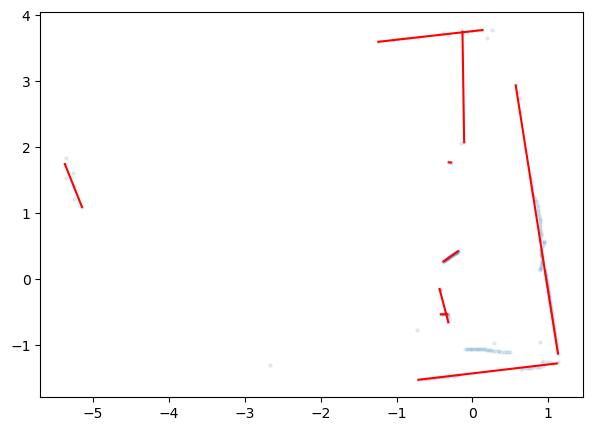

In [24]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(c1.x, c1.y, 5, alpha=0.1)
for i, (a, b) in enumerate(new_lines):
    ax.plot([c1.x[a], c1.x[b]], [c1.y[a], c1.y[b]], color="red")

In [25]:
plt.close("all")

In [26]:
fig, ax = plt.subplots(figsize=(9, 5))

def update(stage):
    ax.clear()
    ax.scatter(c1.x, c1.y, c=c1.range if stage[0] == 1 else c1.strength, cmap="plasma", s = 2, alpha=0.2 if len(stage) > 1 else 1)

    if len(stage) > 1:
        for a, b in stage:
            aa = a % len(points)
            bb = (b - 1) % len(points)
            ax.plot([c1.x[aa], c1.x[bb]], [c1.y[aa], c1.y[bb]], color="red")

anim = FuncAnimation(fig, update, frames=[[0], [1]] + stages, interval=1200, repeat=False)
plt.close(fig)  # Prevents static redundant figure from rendering

# 5. Render interactive player in Jupyter Notebook
HTML(anim.to_jshtml())